# **Library imports**

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import re

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# **Loading Dataset**

In [ ]:
# read dataset from a Google Drive File

file_link = 'https://drive.google.com/file/d/1ObHPfoCLR3CrIwcTrt60CaOx2z5NUQ36/view?usp=sharing'

# get the id part of the file
id = file_link.split("/")[-2]
# print(id)

# creating a new link using the id so that we can easily read the csv file in pandas
new_link = f'https://drive.google.com/uc?id={id}'
print(new_link)
df = pd.read_csv(new_link)

# let's look at the first few instances
df.head(10)

https://drive.google.com/uc?id=1ObHPfoCLR3CrIwcTrt60CaOx2z5NUQ36


/tmp/ipykernel_1140/3874743767.py:12: DtypeWarning: Columns (85) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(new_link)


,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,Label
0,62919,172.16.0.5-192.168.50.1-40269-26964-17,172.16.0.5,40269,192.168.50.1,26964,17,2018-12-01 12:28:05.921889,1,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_SSDP
1,107165,172.16.0.5-192.168.50.1-62937-19353-17,172.16.0.5,62937,192.168.50.1,19353,17,2018-12-01 13:47:16.910885,2,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,TFTP
2,77706,172.16.0.5-192.168.50.4-51727-53885-17,172.16.0.5,51727,192.168.50.4,53885,17,2018-11-03 10:42:48.147266,1,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,MSSQL
3,61695,172.16.0.5-192.168.50.1-63632-42597-17,172.16.0.5,63632,192.168.50.1,42597,17,2018-12-01 13:45:53.992218,3000624,4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,TFTP
4,16257,172.16.0.5-192.168.50.1-896-47568-17,172.16.0.5,896,192.168.50.1,47568,17,2018-12-01 12:15:35.829034,2,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_SNMP
5,206411,172.16.0.5-192.168.50.1-789-40455-17,172.16.0.5,789,192.168.50.1,40455,17,2018-12-01 11:58:26.636372,1,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_NetBIOS
6,92507,172.16.0.5-192.168.50.1-39949-48859-17,172.16.0.5,39949,192.168.50.1,48859,17,2018-12-01 11:44:13.837700,1,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_MSSQL
7,15662,172.16.0.5-192.168.50.4-527-20652-17,172.16.0.5,527,192.168.50.4,20652,17,2018-11-03 10:29:11.053735,2,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,LDAP
8,130921,172.16.0.5-192.168.50.1-55503-49930-17,172.16.0.5,55503,192.168.50.1,49930,17,2018-12-01 11:42:22.256101,1,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_MSSQL
9,14000,172.16.0.5-192.168.50.1-564-44550-17,172.16.0.5,564,192.168.50.1,44550,17,2018-12-01 11:08:52.035444,47,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS


# **Exploratory Data Analysis (EDA)**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 88 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Unnamed: 0                   200000 non-null  int64  
 1   Flow ID                      200000 non-null  object 
 2   Source IP                    200000 non-null  object 
 3   Source Port                  200000 non-null  int64  
 4   Destination IP               200000 non-null  object 
 5   Destination Port             200000 non-null  int64  
 6   Protocol                     200000 non-null  int64  
 7   Timestamp                    200000 non-null  object 
 8   Flow Duration                200000 non-null  int64  
 9   Total Fwd Packets            200000 non-null  int64  
 10  Total Backward Packets       200000 non-null  int64  
 11  Total Length of Fwd Packets  200000 non-null  float64
 12  Total Length of Bwd Packets  200000 non-null  float64
 13 

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,200000.0,NaN,NaN,NaN,89976.59811,115547.353371,0.0,21305.0,53791.0,104839.0,804929.0
Flow ID,200000,199426,172.16.0.5-192.168.50.4-0-0-0,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source IP,200000,61,172.16.0.5,199613,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source Port,200000.0,NaN,NaN,NaN,31776.266715,26325.023807,0.0,875.0,36054.5,61850.0,65532.0
Destination IP,200000,114,192.168.50.1,141868,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
Idle Max,200000.0,NaN,NaN,NaN,221347.11471,2292230.291909,0.0,0.0,0.0,0.0,82067171.0
Idle Min,200000.0,NaN,NaN,NaN,121032.13976,1352219.09413,0.0,0.0,0.0,0.0,82067171.0
SimillarHTTP,200000.0,10.0,0.0,131072.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inbound,200000.0,NaN,NaN,NaN,0.9984,0.039968,0.0,1.0,1.0,1.0,1.0


In [ ]:
# Checking Unique Values
df.nunique()

,0
Unnamed: 0,120112
Flow ID,199426
Source IP,61
Source Port,44836
Destination IP,114
...,...
Idle Max,2168
Idle Min,2167
SimillarHTTP,10
Inbound,2


# **Dataset Preprocessing**

In [ ]:
# checking for missing values
missing = df.isnull().sum()
print(missing[missing > 0])
# Check for infinite values
print("Number of infinite values:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())

Flow Bytes/s    726
dtype: int64
Number of infinite values: 11630


In [ ]:
# Replace infinite values with NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Check missing values again
missing = df.isnull().sum()
print(missing[missing > 0])

Flow Bytes/s      6178
Flow Packets/s    6178
dtype: int64


In [ ]:
# Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("Dataset shape after removing duplicates:", df.shape)

Number of duplicate rows: 4
Dataset shape after removing duplicates: (199996, 88)


In [ ]:
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print(f"Categorical Variables: {len(cat_cols)}")
print(cat_cols)
print(f"Numerical Variables: {len(num_cols)}")
print(num_cols)

Categorical Variables: 6
['Flow ID', 'Source IP', 'Destination IP', 'Timestamp', 'SimillarHTTP', 'Label']
Numerical Variables: 82
['Unnamed: 0', 'Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length St

In [ ]:
df.drop(
    columns=['Flow ID', 'Source IP', 'Destination IP', 'Timestamp','Unnamed: 0'],
    inplace=True,
    errors='ignore')
if ((df['Fwd Header Length'] == df['Fwd Header Length.1']).all()):
  df.drop(columns=['Fwd Header Length.1'], inplace=True)

In [ ]:
constant_cols = df.nunique()[df.nunique() == 1].index.tolist()

print("Constant columns:")
print(constant_cols)

# See their actual values
for col in constant_cols:
    print(f"{col}: {df[col].unique()}")

Constant columns:
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'FIN Flag Count', 'PSH Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Bwd PSH Flags: [0]
Fwd URG Flags: [0]
Bwd URG Flags: [0]
FIN Flag Count: [0]
PSH Flag Count: [0]
ECE Flag Count: [0]
Fwd Avg Bytes/Bulk: [0]
Fwd Avg Packets/Bulk: [0]
Fwd Avg Bulk Rate: [0]
Bwd Avg Bytes/Bulk: [0]
Bwd Avg Packets/Bulk: [0]
Bwd Avg Bulk Rate: [0]


In [ ]:
df.drop(columns=constant_cols, inplace=True)
print("Dropped:", constant_cols)

Dropped: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'FIN Flag Count', 'PSH Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [ ]:
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print(f"Categorical Variables: {len(cat_cols)}")
print(cat_cols)
print(f"Numerical Variables: {len(num_cols)}")
print(num_cols)

Categorical Variables: 2
['SimillarHTTP', 'Label']
Numerical Variables: 68
['Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'SYN Flag Count', 'RST Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 

In [ ]:
print(df[num_cols].describe().T)

                      count          mean           std  min      25%  \
Source Port        199996.0  3.177626e+04  2.632521e+04  0.0    875.0   
Destination Port   199996.0  3.285339e+04  1.891131e+04  0.0  16538.0   
Protocol           199996.0  1.590308e+01  3.296822e+00  0.0     17.0   
Flow Duration      199996.0  1.185043e+06  6.494576e+06  0.0      1.0   
Total Fwd Packets  199996.0  4.271235e+00  1.943871e+02  1.0      2.0   
...                     ...           ...           ...  ...      ...   
Idle Mean          199996.0  1.659711e+05  1.725964e+06  0.0      0.0   
Idle Std           199996.0  4.730817e+04  5.792735e+05  0.0      0.0   
Idle Max           199996.0  2.213515e+05  2.292253e+06  0.0      0.0   
Idle Min           199996.0  1.210346e+05  1.352233e+06  0.0      0.0   
Inbound            199996.0  9.984000e-01  3.996849e-02  0.0      1.0   

                       50%       75%           max  
Source Port        36054.5  61850.00  6.553200e+04  
Destination Port 

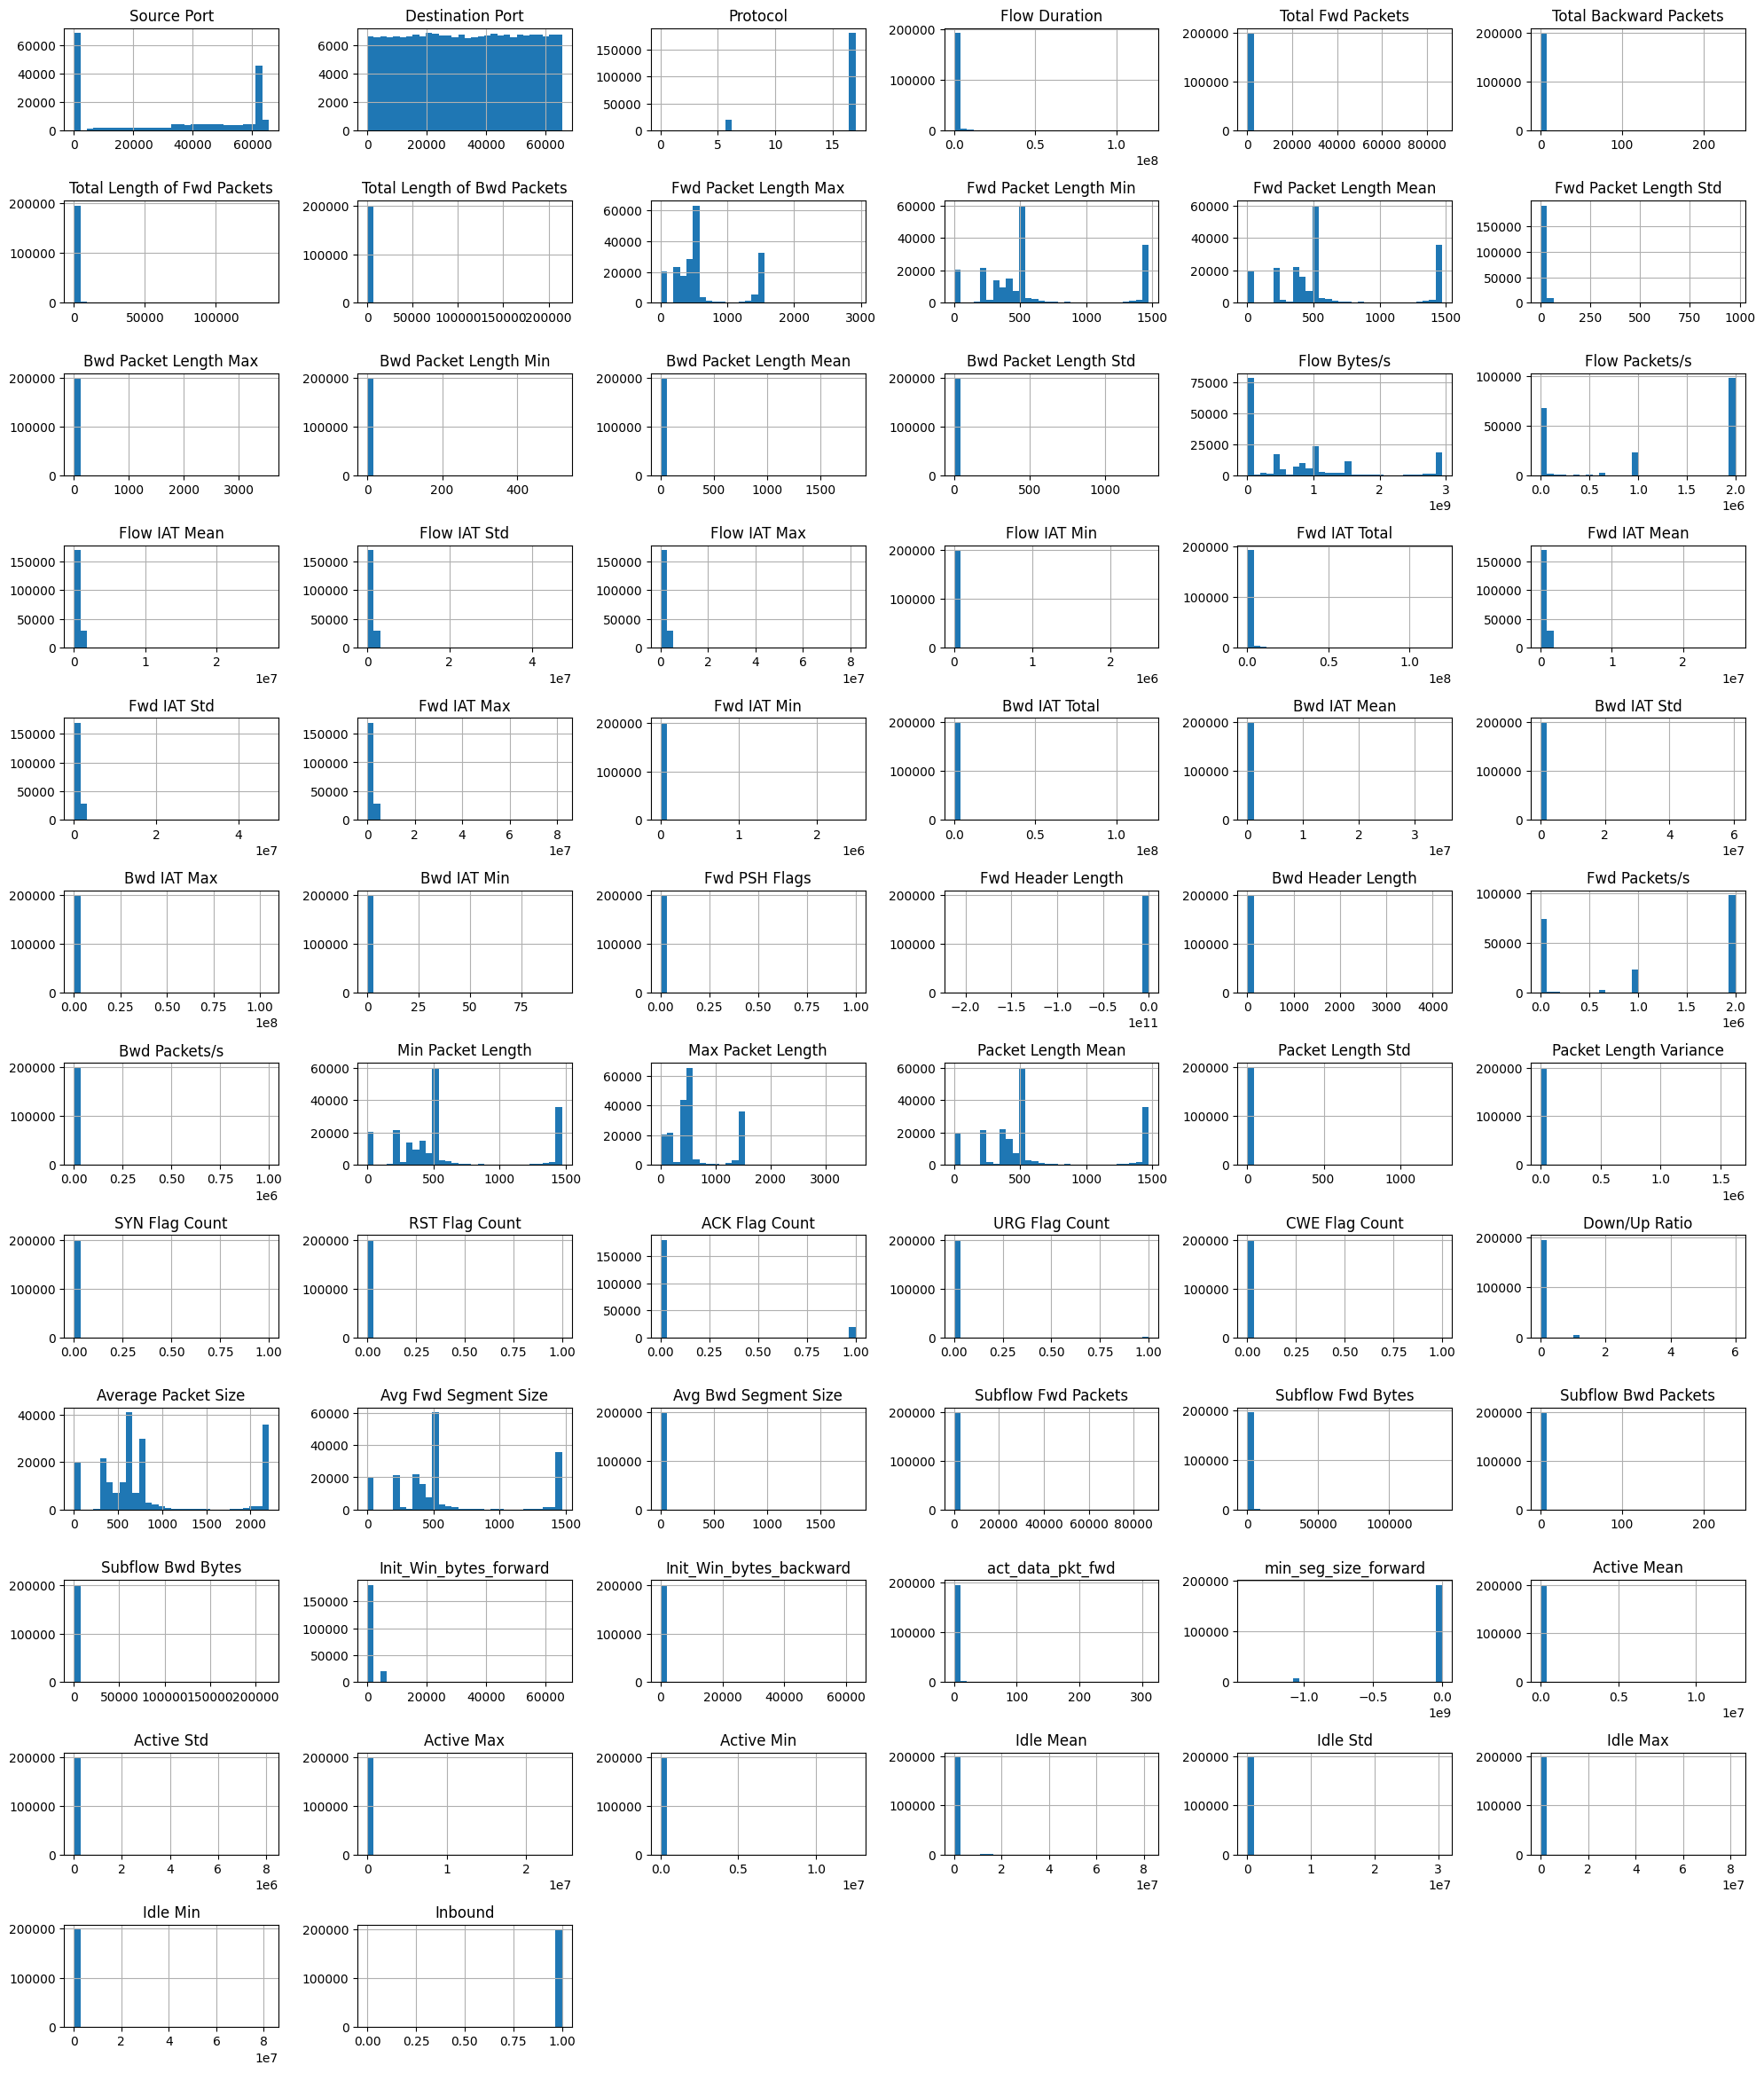

In [ ]:
df[num_cols].hist(
    bins=30,
    figsize=(20, 25),
    layout=(13, 6)
)

plt.tight_layout()
plt.show()

In [ ]:
print(df[num_cols].nunique().sort_values().to_string())

CWE Flag Count                     2
SYN Flag Count                     2
RST Flag Count                     2
ACK Flag Count                     2
URG Flag Count                     2
Fwd PSH Flags                      2
Inbound                            2
Protocol                           3
Down/Up Ratio                      7
Bwd IAT Min                       38
Total Backward Packets            40
Subflow Bwd Packets               40
Bwd Packet Length Min             51
Bwd Packet Length Std             59
Bwd Header Length                 59
Bwd Packet Length Max             82
Init_Win_bytes_backward           84
Avg Bwd Segment Size             105
Bwd Packet Length Mean           107
Init_Win_bytes_forward           109
Total Length of Bwd Packets      114
Subflow Bwd Bytes                114
Active Min                       120
Total Fwd Packets                149
Subflow Fwd Packets              149
act_data_pkt_fwd                 152
Fwd IAT Min                      176
F

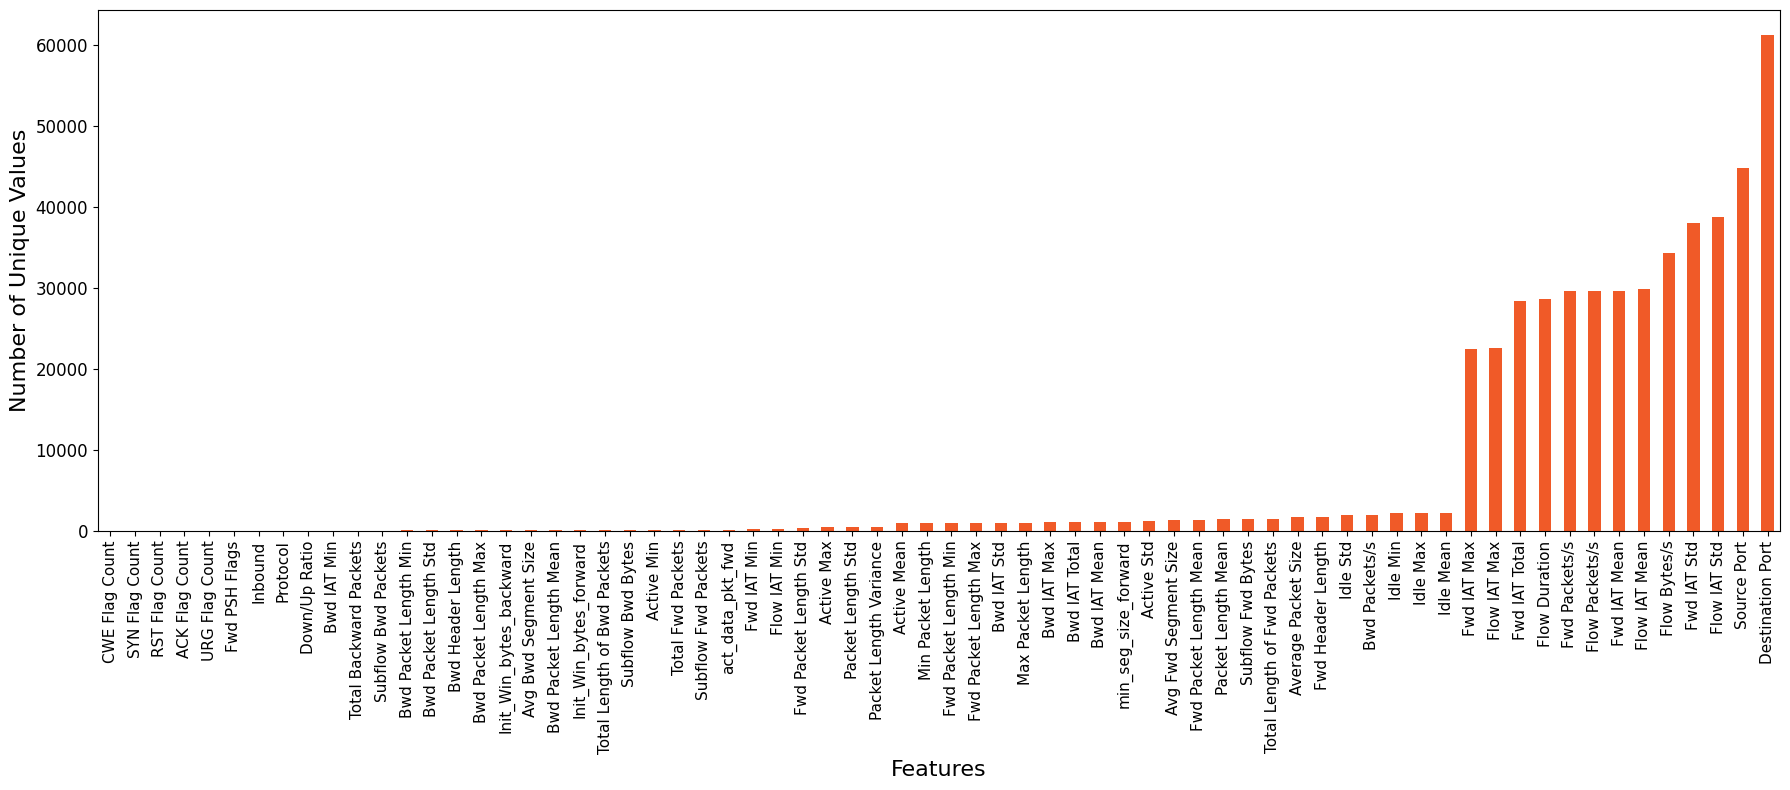

In [ ]:
unique_counts = df[num_cols].nunique().sort_values()

plt.figure(figsize=(18, 8))

unique_counts.plot(
    kind='bar',
    color='#F05A28'
)

plt.xlabel('Features', fontsize=16)
plt.ylabel('Number of Unique Values', fontsize=16)

plt.xticks(rotation=90, fontsize=11)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()





In [ ]:
# Convert categorical variables to numerical
df = pd.get_dummies(
    df,
    columns=['SimillarHTTP'],
    drop_first=True
)
print(df["Label"].value_counts())

Label
TFTP             57030
Syn              18380
MSSQL            16435
DrDoS_SNMP       14653
DrDoS_DNS        14401
DrDoS_MSSQL      12843
DrDoS_NetBIOS    11624
UDP              10982
NetBIOS          10386
DrDoS_UDP         8902
DrDoS_SSDP        7414
DrDoS_LDAP        6191
LDAP              5439
DrDoS_NTP         3415
UDP-lag           1041
Portmap            531
BENIGN             323
UDPLag               5
WebDDoS              1
Name: count, dtype: int64


In [ ]:
df["Label"] = df["Label"].replace({
    "UDP-lag": "UDPLag"})
others_labels = [
    "DrDoS_NTP",
    "UDPLag",
    "Portmap",
    "WebDDoS"]
df["Label"] = df["Label"].replace(others_labels, "Others")
print(df['Label'].value_counts())

Label
TFTP             57030
Syn              18380
MSSQL            16435
DrDoS_SNMP       14653
DrDoS_DNS        14401
DrDoS_MSSQL      12843
DrDoS_NetBIOS    11624
UDP              10982
NetBIOS          10386
DrDoS_UDP         8902
DrDoS_SSDP        7414
DrDoS_LDAP        6191
LDAP              5439
Others            4993
BENIGN             323
Name: count, dtype: int64


In [ ]:
# Clean feature names
df.columns = [
    re.sub(r'[^A-Za-z0-9_]', '_', str(col))
    for col in df.columns
]


# **Final DDoS attack Class Distribution**

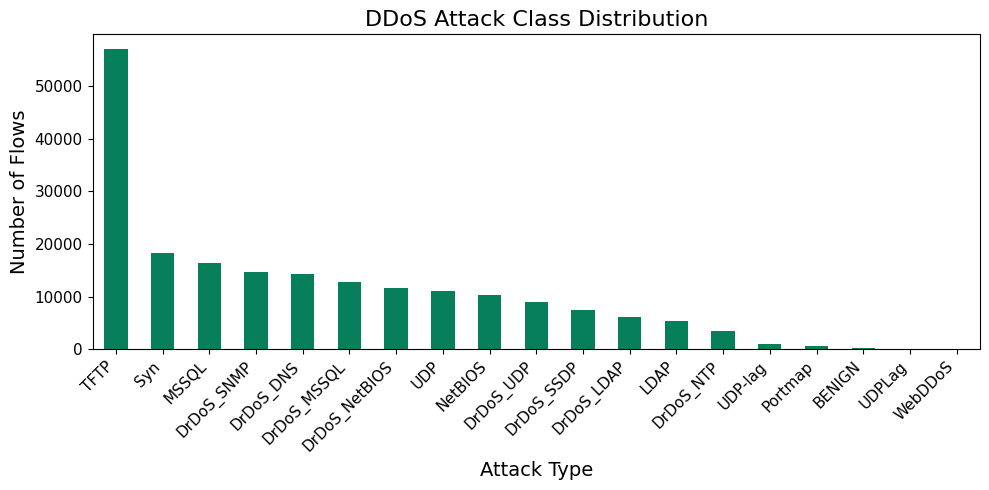

In [ ]:
# Plot label distribution
plt.figure(figsize=(10, 5))

df['Label'].value_counts().plot(
    kind='bar',
    color='#087F5B'
)

plt.title('DDoS Attack Class Distribution', fontsize=16)
plt.xlabel('Attack Type', fontsize=14)
plt.ylabel('Number of Flows', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(fontsize=11)

plt.tight_layout()
plt.show()

In [ ]:
df.shape

(199996, 78)

# **Correlation**

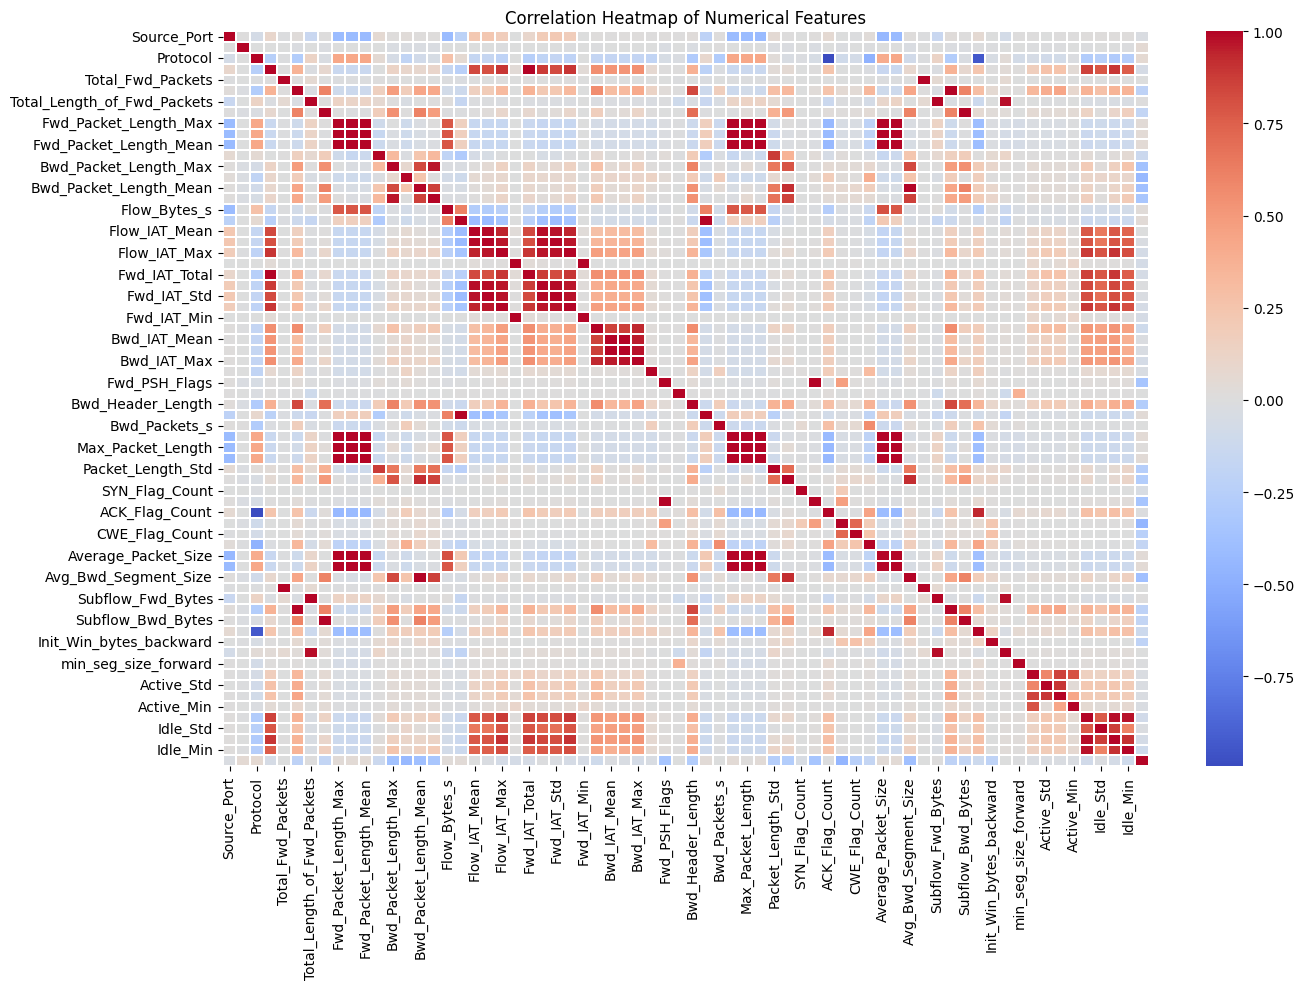

In [ ]:
plt.figure(figsize=(14, 10))

corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    linewidths=0.1
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

# **Model Training**

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. LightGBM
5. XGBoost
6. Gradient Boosting
7. Multi-Layer Perceptron (MLP)

In [ ]:
# Separate features and target
X = df.drop('Label', axis=1)
y = df['Label']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (199996, 77)
Target shape: (199996,)


In [ ]:
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("Encoded classes:")
print(label_encoder.classes_)

Encoded classes:
['BENIGN' 'DrDoS_DNS' 'DrDoS_LDAP' 'DrDoS_MSSQL' 'DrDoS_NetBIOS'
 'DrDoS_SNMP' 'DrDoS_SSDP' 'DrDoS_UDP' 'LDAP' 'MSSQL' 'NetBIOS' 'Others'
 'Syn' 'TFTP' 'UDP']


In [ ]:
# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


# Median Imputation
train_medians = X_train.median(numeric_only=True)

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("Missing values after imputation:")
print("Training:", X_train.isnull().sum().sum())
print("Testing:", X_test.isnull().sum().sum())

Training set: (159996, 77)
Testing set: (40000, 77)
Missing values after imputation:
Training: 0
Testing: 0


# **Logistic Regression**

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

y_pred_lr = logistic_model.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, average='weighted', zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, average='weighted', zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, average='weighted', zero_division=0)

print("Logistic Regression")
print("-------------------")
print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)

Logistic Regression
-------------------
Accuracy : 0.619275
Precision: 0.5790740158695986
Recall   : 0.619275
F1 Score : 0.5573149780408777


### Classification Report (Logistic Regression)

In [ ]:
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=label_encoder.classes_,
    zero_division=0
))

               precision    recall  f1-score   support

       BENIGN       0.95      0.86      0.90        65
    DrDoS_DNS       0.45      0.65      0.53      2880
   DrDoS_LDAP       0.20      0.00      0.00      1238
  DrDoS_MSSQL       0.38      0.02      0.05      2569
DrDoS_NetBIOS       0.50      0.76      0.61      2325
   DrDoS_SNMP       0.57      0.73      0.64      2931
   DrDoS_SSDP       0.41      0.03      0.05      1483
    DrDoS_UDP       0.37      0.01      0.03      1780
         LDAP       0.25      0.01      0.02      1088
        MSSQL       0.42      0.47      0.44      3287
      NetBIOS       0.50      0.30      0.38      2077
       Others       0.97      0.65      0.77       999
          Syn       0.94      1.00      0.97      3676
         TFTP       0.74      0.92      0.82     11406
          UDP       0.41      0.84      0.55      2196

     accuracy                           0.62     40000
    macro avg       0.54      0.48      0.45     40000
 weighte

# **Decision Tree**

In [ ]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, average='weighted', zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, average='weighted', zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, average='weighted', zero_division=0)

print("Decision Tree")
print("-------------")
print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1 Score :", dt_f1)

Decision Tree
-------------
Accuracy : 0.6878
Precision: 0.68844146210094
Recall   : 0.6878
F1 Score : 0.6880950270394379


### Classification Report (Decision Tree)

In [ ]:
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=label_encoder.classes_,
    zero_division=0
))

               precision    recall  f1-score   support

       BENIGN       0.97      0.98      0.98        65
    DrDoS_DNS       0.63      0.62      0.63      2880
   DrDoS_LDAP       0.25      0.26      0.26      1238
  DrDoS_MSSQL       0.45      0.45      0.45      2569
DrDoS_NetBIOS       0.55      0.56      0.55      2325
   DrDoS_SNMP       0.70      0.68      0.69      2931
   DrDoS_SSDP       0.29      0.30      0.30      1483
    DrDoS_UDP       0.35      0.34      0.35      1780
         LDAP       0.26      0.26      0.26      1088
        MSSQL       0.57      0.57      0.57      3287
      NetBIOS       0.53      0.52      0.53      2077
       Others       0.70      0.72      0.71       999
          Syn       0.95      0.95      0.95      3676
         TFTP       0.99      0.99      0.99     11406
          UDP       0.48      0.47      0.48      2196

     accuracy                           0.69     40000
    macro avg       0.58      0.58      0.58     40000
 weighte

# **Random Forest**

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, average='weighted', zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, average='weighted', zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, average='weighted', zero_division=0)

print("Random Forest")
print("-------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)

Random Forest
-------------
Accuracy : 0.72215
Precision: 0.715756678033471
Recall   : 0.72215
F1 Score : 0.7178843673557646


### Classification Report (Random Forest)

In [ ]:
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=label_encoder.classes_,
    zero_division=0
))

               precision    recall  f1-score   support

       BENIGN       0.90      0.98      0.94        65
    DrDoS_DNS       0.65      0.71      0.68      2880
   DrDoS_LDAP       0.29      0.21      0.25      1238
  DrDoS_MSSQL       0.50      0.46      0.48      2569
DrDoS_NetBIOS       0.58      0.61      0.60      2325
   DrDoS_SNMP       0.75      0.80      0.78      2931
   DrDoS_SSDP       0.35      0.28      0.31      1483
    DrDoS_UDP       0.38      0.36      0.37      1780
         LDAP       0.32      0.27      0.29      1088
        MSSQL       0.60      0.65      0.62      3287
      NetBIOS       0.56      0.56      0.56      2077
       Others       0.87      0.71      0.78       999
          Syn       0.94      0.99      0.96      3676
         TFTP       1.00      0.99      1.00     11406
          UDP       0.51      0.57      0.54      2196

     accuracy                           0.72     40000
    macro avg       0.61      0.61      0.61     40000
 weighte

# **LightGBM**

In [ ]:
lgb_model = LGBMClassifier(
    objective='multiclass',
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(X_train, y_train)

y_pred_lgb = lgb_model.predict(X_test)

# Performance Metrics
lgb_accuracy = accuracy_score(y_test, y_pred_lgb)

lgb_precision = precision_score(
    y_test,
    y_pred_lgb,
    average='weighted',
    zero_division=0
)

lgb_recall = recall_score(
    y_test,
    y_pred_lgb,
    average='weighted',
    zero_division=0
)

lgb_f1 = f1_score(
    y_test,
    y_pred_lgb,
    average='weighted',
    zero_division=0
)

print("LightGBM")
print("--------")
print("Accuracy :", lgb_accuracy)
print("Precision:", lgb_precision)
print("Recall   :", lgb_recall)
print("F1 Score :", lgb_f1)

LightGBM
--------
Accuracy : 0.7574
Precision: 0.7501443723758291
Recall   : 0.7574
F1 Score : 0.7437305041890216


### Classification Report (LightGBM)

In [ ]:
print(classification_report(
    y_test,
    y_pred_lgb,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97        65
           1       0.65      0.81      0.72      2880
           2       0.48      0.17      0.25      1238
           3       0.62      0.38      0.47      2569
           4       0.62      0.76      0.68      2325
           5       0.77      0.86      0.81      2931
           6       0.40      0.17      0.24      1483
           7       0.40      0.44      0.42      1780
           8       0.42      0.27      0.33      1088
           9       0.62      0.83      0.71      3287
          10       0.66      0.57      0.61      2077
          11       0.97      0.70      0.81       999
          12       0.94      1.00      0.97      3676
          13       1.00      0.99      1.00     11406
          14       0.54      0.69      0.60      2196

    accuracy                           0.76     40000
   macro avg       0.67      0.64      0.64     40000
weighted avg       0.75   

# **XGBoost**

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

xgb_precision = precision_score(
    y_test,
    y_pred_xgb,
    average='weighted',
    zero_division=0
)

xgb_recall = recall_score(
    y_test,
    y_pred_xgb,
    average='weighted',
    zero_division=0
)

xgb_f1 = f1_score(
    y_test,
    y_pred_xgb,
    average='weighted',
    zero_division=0
)

print("XGBoost")
print("-------")
print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1 Score :", xgb_f1)

XGBoost
-------
Accuracy : 0.7501
Precision: 0.7457487727816
Recall   : 0.7501
F1 Score : 0.7238642112328856


### Classification Report (XGBoost)

In [ ]:
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=label_encoder.classes_,
    zero_division=0
))

               precision    recall  f1-score   support

       BENIGN       0.96      0.98      0.97        65
    DrDoS_DNS       0.62      0.83      0.71      2880
   DrDoS_LDAP       0.55      0.15      0.24      1238
  DrDoS_MSSQL       0.61      0.20      0.30      2569
DrDoS_NetBIOS       0.61      0.77      0.68      2325
   DrDoS_SNMP       0.76      0.87      0.81      2931
   DrDoS_SSDP       0.45      0.09      0.15      1483
    DrDoS_UDP       0.43      0.33      0.37      1780
         LDAP       0.45      0.21      0.28      1088
        MSSQL       0.58      0.90      0.70      3287
      NetBIOS       0.66      0.54      0.59      2077
       Others       0.98      0.70      0.82       999
          Syn       0.94      1.00      0.97      3676
         TFTP       1.00      0.99      1.00     11406
          UDP       0.49      0.83      0.62      2196

     accuracy                           0.75     40000
    macro avg       0.67      0.63      0.61     40000
 weighte

# **GRADIENT BOOSTING**

In [ ]:
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

gb_accuracy = accuracy_score(y_test, y_pred_gb)

gb_precision = precision_score(
    y_test,
    y_pred_gb,
    average='weighted',
    zero_division=0
)

gb_recall = recall_score(
    y_test,
    y_pred_gb,
    average='weighted',
    zero_division=0
)

gb_f1 = f1_score(
    y_test,
    y_pred_gb,
    average='weighted',
    zero_division=0
)

print("Gradient Boosting")
print("-----------------")
print("Accuracy :", gb_accuracy)
print("Precision:", gb_precision)
print("Recall   :", gb_recall)
print("F1 Score :", gb_f1)

Gradient Boosting
-----------------
Accuracy : 0.750575
Precision: 0.7458559221281669
Recall   : 0.750575
F1 Score : 0.7275071787121039


### Classification Report (Gradient Boosting)

In [ ]:
print(classification_report(
    y_test,
    y_pred_gb,
    target_names=label_encoder.classes_,
    zero_division=0
))

               precision    recall  f1-score   support

       BENIGN       0.96      0.98      0.97        65
    DrDoS_DNS       0.62      0.84      0.71      2880
   DrDoS_LDAP       0.56      0.13      0.20      1238
  DrDoS_MSSQL       0.58      0.22      0.32      2569
DrDoS_NetBIOS       0.61      0.78      0.69      2325
   DrDoS_SNMP       0.76      0.86      0.81      2931
   DrDoS_SSDP       0.45      0.10      0.17      1483
    DrDoS_UDP       0.40      0.47      0.43      1780
         LDAP       0.46      0.23      0.30      1088
        MSSQL       0.58      0.88      0.70      3287
      NetBIOS       0.66      0.54      0.59      2077
       Others       0.98      0.70      0.82       999
          Syn       0.94      1.00      0.97      3676
         TFTP       1.00      0.99      1.00     11406
          UDP       0.52      0.71      0.60      2196

     accuracy                           0.75     40000
    macro avg       0.67      0.63      0.62     40000
 weighte

# **MLP**

In [ ]:
mlp_model = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation='relu',
    solver='adam',
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

mlp_model.fit(X_train_scaled, y_train)

y_pred_mlp = mlp_model.predict(X_test_scaled)

# Performance Metrics
mlp_accuracy = accuracy_score(y_test, y_pred_mlp)

mlp_precision = precision_score(
    y_test,
    y_pred_mlp,
    average='weighted',
    zero_division=0
)

mlp_recall = recall_score(
    y_test,
    y_pred_mlp,
    average='weighted',
    zero_division=0
)

mlp_f1 = f1_score(
    y_test,
    y_pred_mlp,
    average='weighted',
    zero_division=0
)

print("MLP")
print("---")
print("Accuracy :", mlp_accuracy)
print("Precision:", mlp_precision)
print("Recall   :", mlp_recall)
print("F1 Score :", mlp_f1)

MLP
---
Accuracy : 0.7068
Precision: 0.6686913688088789
Recall   : 0.7068
F1 Score : 0.6422308044510475


### Classification Report (MLP)

In [ ]:
print(classification_report(
    y_test,
    y_pred_mlp,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.97      0.94      0.95        65
           1       0.52      0.84      0.64      2880
           2       0.00      0.00      0.00      1238
           3       0.45      0.01      0.02      2569
           4       0.52      0.84      0.64      2325
           5       0.72      0.81      0.76      2931
           6       0.44      0.02      0.04      1483
           7       0.36      0.04      0.07      1780
           8       0.00      0.00      0.00      1088
           9       0.54      0.94      0.69      3287
          10       0.55      0.24      0.33      2077
          11       0.98      0.67      0.80       999
          12       0.93      1.00      0.96      3676
          13       0.98      0.99      0.99     11406
          14       0.41      0.94      0.57      2196

    accuracy                           0.71     40000
   macro avg       0.56      0.55      0.50     40000
weighted avg       0.67   

# **Model Comparison**

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'LightGBM',
        'XGBoost',
        'Gradient Boosting',
        'MLP'
    ],

    'Accuracy': [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        lgb_accuracy,
        xgb_accuracy,
        gb_accuracy,
        mlp_accuracy
    ],

    'Precision': [
        lr_precision,
        dt_precision,
        rf_precision,
        lgb_precision,
        xgb_precision,
        gb_precision,
        mlp_precision
    ],

    'Recall': [
        lr_recall,
        dt_recall,
        rf_recall,
        lgb_recall,
        xgb_recall,
        gb_recall,
        mlp_recall
    ],

    'F1 Score': [
        lr_f1,
        dt_f1,
        rf_f1,
        lgb_f1,
        xgb_f1,
        gb_f1,
        mlp_f1
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.619275,0.579074,0.619275,0.557315
1,Decision Tree,0.687800,0.688441,0.687800,0.688095
2,Random Forest,0.722150,0.715757,0.722150,0.717884
3,LightGBM,0.757400,0.750144,0.757400,0.743731
4,XGBoost,0.750100,0.745749,0.750100,0.723864
5,Gradient Boosting,0.750575,0.745856,0.750575,0.727507
6,MLP,0.706800,0.668691,0.706800,0.642231


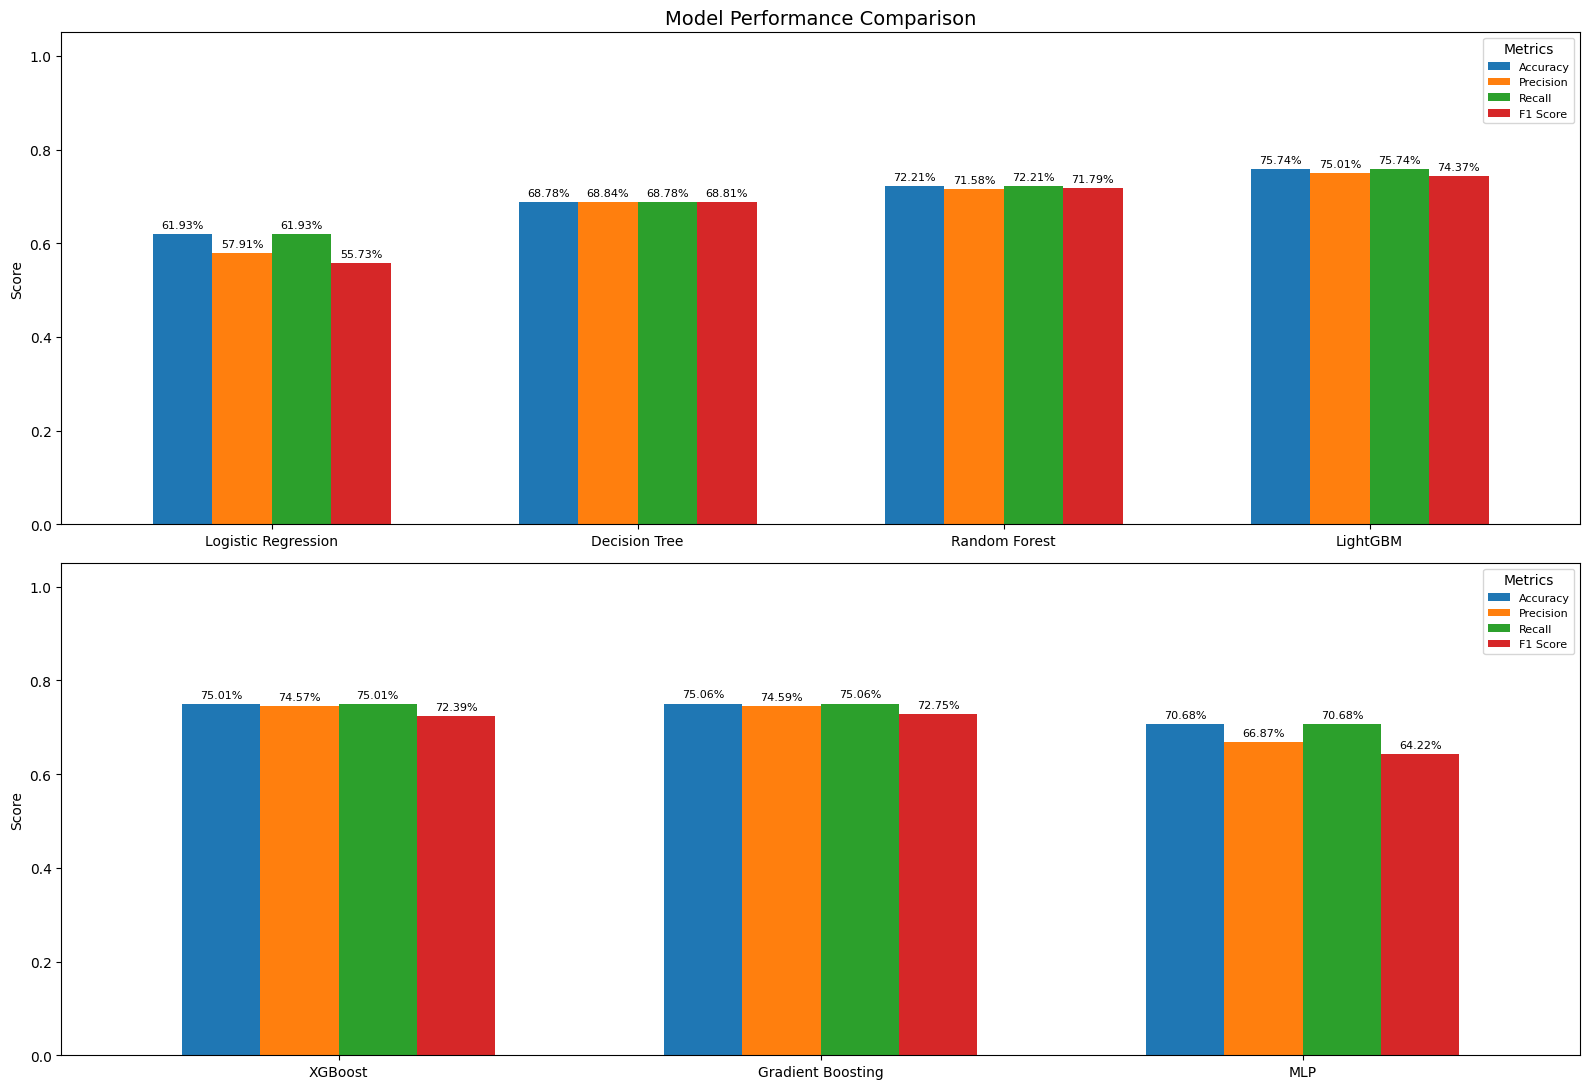

In [ ]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 11)
)

model_groups = [
    ['Logistic Regression', 'Decision Tree', 'Random Forest', 'LightGBM'],
    ['XGBoost', 'Gradient Boosting', 'MLP']
]

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

for ax, group in zip(axes, model_groups):

    results[results['Model'].isin(group)].set_index('Model')[metrics].plot(
        kind='bar',
        ax=ax,
        width=0.65
    )

    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Score')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)

    for container in ax.containers:
        ax.bar_label(
            container,
            labels=[
                f'{bar.get_height() * 100:.2f}%'
                for bar in container
            ],
            padding=3,
            fontsize=8
        )

    ax.legend(
        title='Metrics',
        fontsize=8
    )

axes[0].set_title('Model Performance Comparison', fontsize=14)

plt.tight_layout()

plt.savefig(
    'model_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

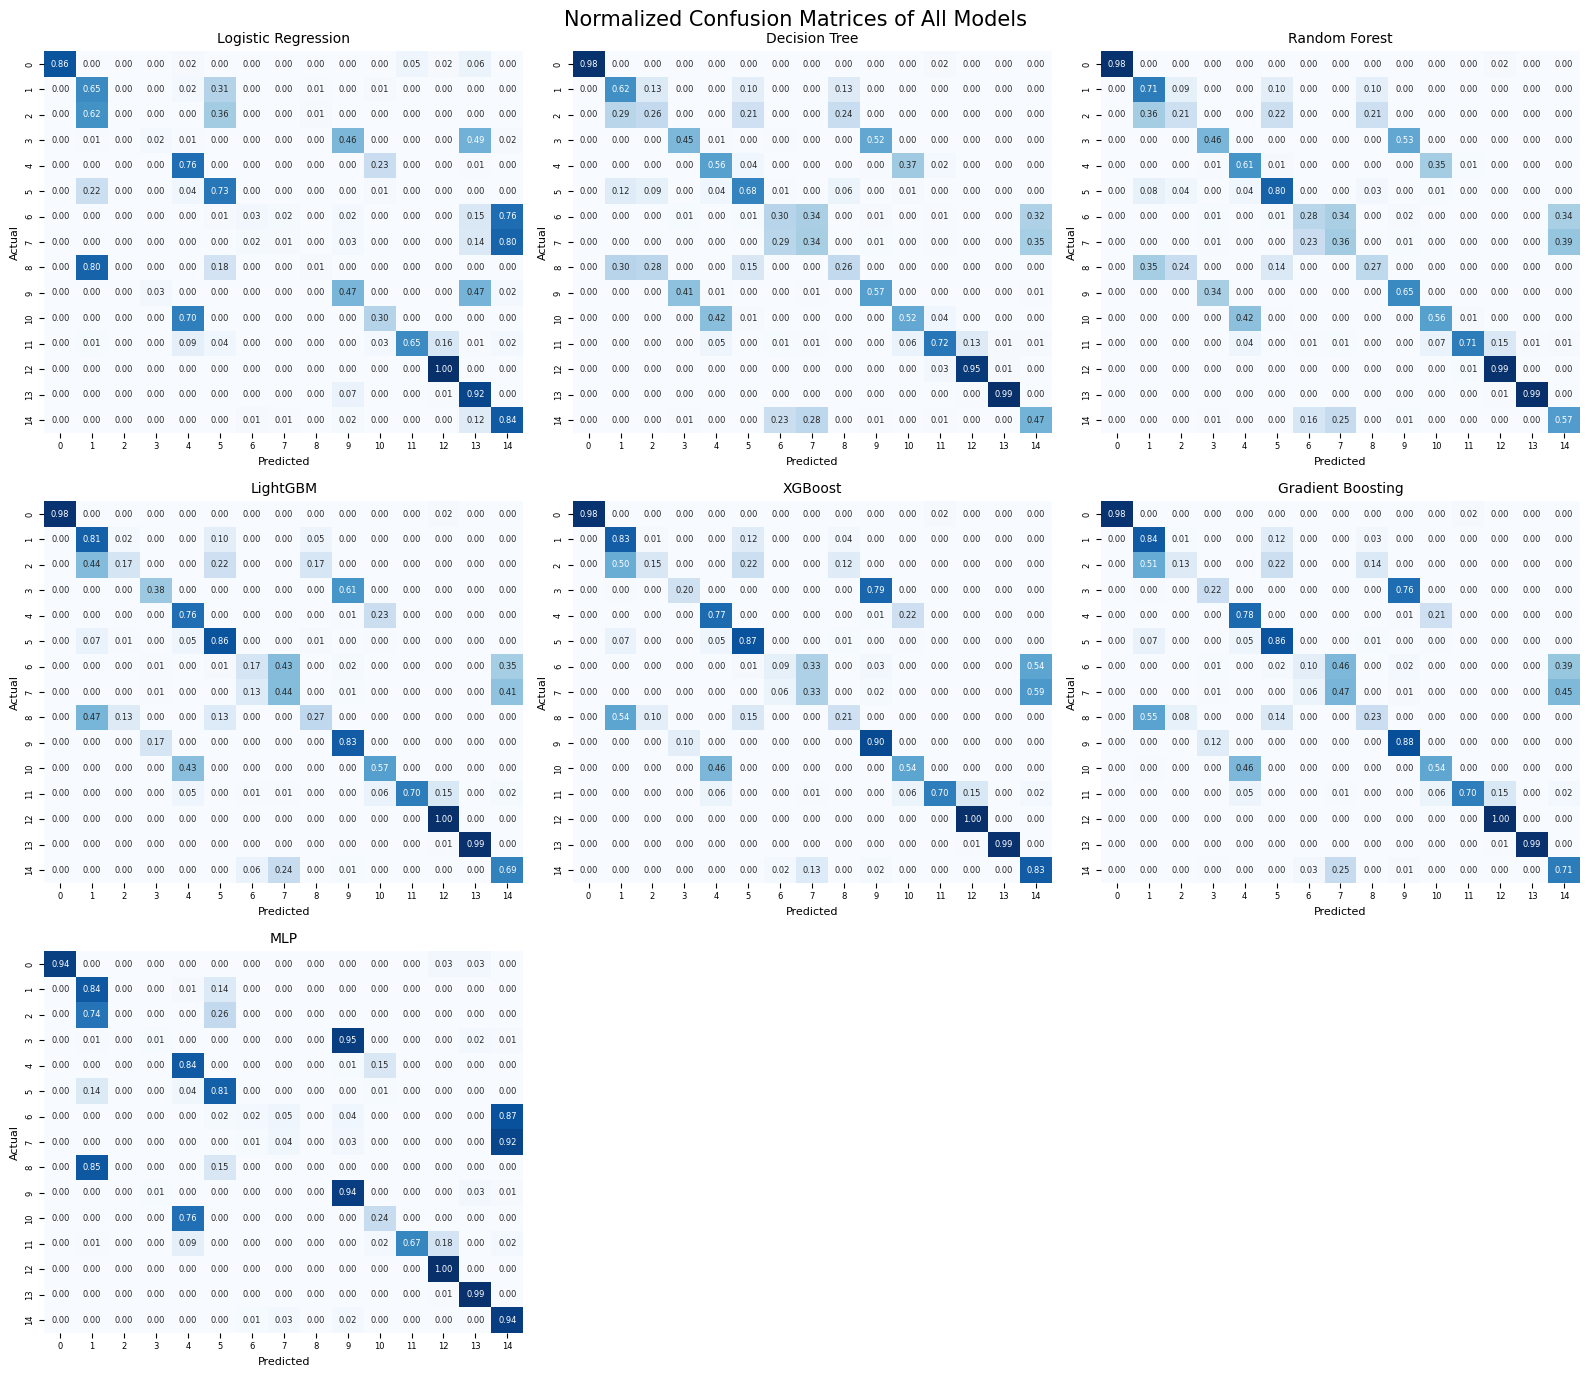

In [ ]:
predictions = {
    'Logistic Regression': y_pred_lr,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'LightGBM': y_pred_lgb,
    'XGBoost': y_pred_xgb,
    'Gradient Boosting': y_pred_gb,
    'MLP': y_pred_mlp
}

class_names = np.unique(y_test)

fig, axes = plt.subplots(
    3, 3,
    figsize=(16, 14)
)

axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(predictions.items()):

    cm_normalized = confusion_matrix(
        y_test,
        y_pred,
        normalize='true'
    )

    sns.heatmap(
        cm_normalized,
        annot=True,
        fmt='.2f',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=axes[i],
        cbar=False,
        annot_kws={'fontsize': 6}
    )

    axes[i].set_title(
        model_name,
        fontsize=10
    )

    axes[i].set_xlabel(
        'Predicted',
        fontsize=8
    )

    axes[i].set_ylabel(
        'Actual',
        fontsize=8
    )

    axes[i].tick_params(
        axis='both',
        labelsize=6
    )

# Hide the two unused panels
for i in range(len(predictions), len(axes)):
    axes[i].axis('off')

plt.suptitle(
    'Normalized Confusion Matrices of All Models',
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    'all_model_confusion_matrices.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()